# SafeRoute — Modelo de Predição de Acidentes Fatais

**Sprint 2 — notebook consolidado e definitivo.** Rode de cima para baixo
(`Ambiente de execução → Executar tudo`). Linear, sem estado oculto, cada
variável definida uma única vez. Substitui as versões anteriores
(`Notebook_SafeRoute`, `_V2`, `_Spotlight`), que podem ser descartadas.

Pipeline: carga → limpeza (com correção de data) → engenharia de atributos →
target binário (fatal vs não-fatal) → split → treino → avaliação (AUC, threshold)
→ conclusões (importância de atributos e cruzamentos).


## 1. Importações e carregamento dos dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

!pip install -q imbalanced-learn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

sns.set_style("whitegrid")

In [ ]:
import io

ARQUIVO = "datatran2025.csv"

def carregar_prf(caminho):
    """Carrega o CSV da PRF PRESERVANDO as aspas.

    As aspas são necessárias: são elas que mantêm valores como "Aclive;Reta"
    em uma coluna só (o separador do arquivo também é ';'). Removê-las
    desalinha a tabela inteira.

    Linhas com número ímpar de aspas (uma aspa aberta e nunca fechada) são
    descartadas antes da leitura. Sem isso, o pandas ou falha com
    'EOF inside string', ou -- pior -- funde silenciosamente duas linhas
    em uma só, sem dar erro nenhum.
    """
    with open(caminho, encoding="latin1") as f:
        linhas = [f.readline()]  # cabeçalho
        descartadas = 0
        for linha in f:
            if linha.count('"') % 2 == 0:
                linhas.append(linha)
            else:
                descartadas += 1
    df = pd.read_csv(io.StringIO("".join(linhas)), sep=";", low_memory=False)
    return df, descartadas

df, linhas_descartadas = carregar_prf(ARQUIVO)

# Remove espaços sobrando no início/fim dos textos
df.columns = df.columns.str.strip()
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print(f"Registros: {df.shape[0]:,} | Colunas: {df.shape[1]} | Linhas descartadas: {linhas_descartadas}")
df.head()

Registros: 72,529 | Colunas: 30 | Linhas descartadas: 0


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,652493,2025-01-01,quarta-feira,06:20:00,SP,116,225,GUARULHOS,Reação tardia ou ineficiente do condutor,Tombamento,...,0,0,1,1,2,"-23,48586772","-46,54075317",SPRF-SP,DEL01-SP,UOP01-DEL01-SP
1,652519,2025-01-01,quarta-feira,07:50:00,CE,116,"546,2",PENAFORTE,Pista esburacada,Colisão frontal,...,0,1,4,1,6,"-7,812288","-39,08333306",SPRF-CE,DEL05-CE,UOP03-DEL05-CE
2,652522,2025-01-01,quarta-feira,08:45:00,PR,369,"88,2",CORNELIO PROCOPIO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,2,0,3,2,"-23,182565","-50,637228",SPRF-PR,DEL07-PR,UOP05-DEL07-PR
3,652544,2025-01-01,quarta-feira,11:00:00,PR,116,74,CAMPINA GRANDE DO SUL,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,0,4,0,1,2,"-25,36517687","-49,04223028",SPRF-PR,DEL01-PR,UOP02-DEL01-PR
4,652549,2025-01-01,quarta-feira,09:30:00,MG,251,471,FRANCISCO SA,Velocidade Incompatível,Colisão frontal,...,1,1,2,2,4,"-16,46801304","-43,43121303",SPRF-MG,DEL12-MG,UOP01-DEL12-MG


In [ ]:
# CHECAGEM DE ALINHAMENTO — se algo estiver fora do lugar, o notebook
# para AQUI com uma mensagem clara (em vez de quebrar lá na frente).

esperadas = ["id", "data_inversa", "horario", "br", "km",
             "classificacao_acidente", "latitude", "longitude", "veiculos"]
faltando = [c for c in esperadas if c not in df.columns]
assert not faltando, f"Colunas ausentes no CSV: {faltando}"

# Se o pandas transformou a 1ª coluna em índice, as colunas estão deslocadas
assert isinstance(df.index, pd.RangeIndex), (
    "O índice não é sequencial: as colunas estão deslocadas (linhas com "
    "mais campos que o cabeçalho). Verifique a carga do arquivo."
)

ids_numericos = pd.to_numeric(df["id"], errors="coerce").notna().mean()
assert ids_numericos > 0.99, f"Só {ids_numericos:.0%} da coluna 'id' é numérica — colunas desalinhadas!"

classif_ok = df["classificacao_acidente"].dropna().str.contains("tima").mean()
assert classif_ok > 0.99, "'classificacao_acidente' não contém 'Com/Sem Vítimas' — colunas desalinhadas!"

# Nenhuma linha pode ter sumido "por baixo dos panos" (ex.: on_bad_lines='skip'
# descartando todos os acidentes com traçado composto, como "Curva;Declive")
with open(ARQUIVO, encoding="latin1") as f:
    linhas_no_arquivo = sum(1 for linha in f if linha.strip()) - 1  # menos o cabeçalho
perdidas = linhas_no_arquivo - len(df)
assert perdidas <= 0.01 * linhas_no_arquivo, (
    f"{perdidas:,} de {linhas_no_arquivo:,} linhas do arquivo não foram carregadas — "
    "algo na carga está descartando dados."
)

print(f"Alinhamento OK — colunas no lugar certo. "
      f"Linhas do arquivo não carregadas: {perdidas:,} de {linhas_no_arquivo:,}.")
print(df["classificacao_acidente"].value_counts())

Alinhamento OK — colunas no lugar certo. Linhas do arquivo não carregadas: 0 de 72,529.
classificacao_acidente
Com Vítimas Feridas    56181
Sem Vítimas            11138
Com Vítimas Fatais      5209
Name: count, dtype: int64


## 2. Limpeza e correção de tipos

**Correção da data (ISO):** o CSV da PRF traz `data_inversa` no formato
`YYYY-MM-DD`; por isso usamos `format="%Y-%m-%d"` (e NÃO `dayfirst=True`, que
quebraria o parsing e geraria `NaN` em mês/dia-da-semana). Também corrige o
separador decimal com vírgula.

In [ ]:
# Números com vírgula decimal (padrão brasileiro) -> float
for col in ["latitude", "longitude", "km", "veiculos", "br"]:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.replace(",", ".", regex=False),
            errors="coerce"
        )
df["br"] = df["br"].astype("Int64")  # 116.0 -> 116

# Data: formato ISO (AAAA-MM-DD), com fallback para DD/MM/AAAA
# (alguns anos da PRF usam o formato brasileiro)
datas_iso = pd.to_datetime(df["data_inversa"], format="%Y-%m-%d", errors="coerce")
datas_br = pd.to_datetime(df["data_inversa"], format="%d/%m/%Y", errors="coerce")
df["data_inversa"] = datas_iso.fillna(datas_br)

df["hora"] = pd.to_datetime(df["horario"], format="%H:%M:%S", errors="coerce").dt.hour

# Padroniza o nome da coluna de condição meteorológica (varia entre anos)
for cand in ["condicao_metereologica", "condicao_meteorologica", "cond_meteorologica"]:
    if cand in df.columns:
        df = df.rename(columns={cand: "condicao_meteorologica"})
        break

n_nat = df["data_inversa"].isna().sum()
print(f"Datas não convertidas: {n_nat:,} de {len(df):,}")
assert n_nat < 0.01 * len(df), "Mais de 1% das datas não converteu — confira o formato de data_inversa."
print("Limpeza concluída.")

Datas não convertidas: 0 de 72,529
Limpeza concluída.


## 3. Atributos temporais e chave de segmento rodoviário

In [ ]:
df["dia_semana_num"] = df["data_inversa"].dt.dayofweek  # 0 = segunda
df["mes"] = df["data_inversa"].dt.month
df["ano"] = df["data_inversa"].dt.year

# Conferência: mês e dia da semana não podem estar todos vazios
print("Amostra temporal:")
print(df[["data_inversa", "mes", "dia_semana_num", "hora"]].head())

TAMANHO_SEGMENTO_KM = 5
df["km_segmento"] = (df["km"] // TAMANHO_SEGMENTO_KM) * TAMANHO_SEGMENTO_KM
df["segmento_id"] = df["br"].astype(str) + "_KM" + df["km_segmento"].astype(str)
print(f"\nSegmentos únicos: {df['segmento_id'].nunique():,}")

Amostra temporal:
  data_inversa  mes  dia_semana_num  hora
0   2025-01-01    1               2     6
1   2025-01-01    1               2     7
2   2025-01-01    1               2     8
3   2025-01-01    1               2    11
4   2025-01-01    1               2     9

Segmentos únicos: 5,963


## 4. Definição do target binário

O modelo responde **"este acidente tem risco de morte?"** — 1 = fatal,
0 = não-fatal. Alinha-se ao objetivo do SafeRoute e torna o desbalanceamento
tratável como problema binário.

In [ ]:
TARGET_ORIGINAL = "classificacao_acidente"

# 1 = "Com Vítimas Fatais", 0 = demais classes
# Atenção: buscar "Fatal" NÃO funciona — "Fatais" não contém "Fatal".
df["target_binario"] = (
    df[TARGET_ORIGINAL].str.contains("fatais", case=False, na=False).astype(int)
)

print("Distribuição do target (0 = não-fatal, 1 = fatal):")
print(df["target_binario"].value_counts())
print((df["target_binario"].value_counts(normalize=True) * 100).round(2))

assert df["target_binario"].nunique() == 2, "O target ficou com uma classe só — confira a carga dos dados."

Distribuição do target (0 = não-fatal, 1 = fatal):
target_binario
0    67320
1     5209
Name: count, dtype: int64
target_binario
0    92.82
1     7.18
Name: proportion, dtype: float64


## 5. Seleção de atributos (com remoção de vazamento)

`mortos`, `feridos*`, `ilesos`, `pessoas` derivam do alvo — ficam de fora
(vazamento de dados).

In [ ]:
features_categoricas = [c for c in [
    "causa_acidente", "tipo_acidente", "fase_dia", "condicao_meteorologica",
    "tipo_pista", "tracado_via", "uso_solo", "sentido_via", "uf"
] if c in df.columns]

features_numericas = [c for c in [
    "hora", "mes", "dia_semana_num", "veiculos", "latitude", "longitude"
] if c in df.columns]

print("Categóricas:", features_categoricas)
print("Numéricas:  ", features_numericas)

colunas = features_categoricas + features_numericas + ["segmento_id", "target_binario"]
df_modelo = df[colunas].dropna(subset=["target_binario"]).copy()
print(f"\nRegistros para modelagem: {len(df_modelo):,}")

Categóricas: ['causa_acidente', 'tipo_acidente', 'fase_dia', 'condicao_meteorologica', 'tipo_pista', 'tracado_via', 'uso_solo', 'sentido_via', 'uf']
Numéricas:   ['hora', 'mes', 'dia_semana_num', 'veiculos', 'latitude', 'longitude']

Registros para modelagem: 72,529


## 6. Divisão treino/teste

Split **antes** de calcular o risco por segmento, para não vazar informação.

In [ ]:
X = df_modelo[features_categoricas + features_numericas + ["segmento_id"]]
y = df_modelo["target_binario"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Treino: {len(X_train):,} | Teste: {len(X_test):,}")

Treino: 58,023 | Teste: 14,506


## 7. Feature de risco histórico por segmento

Calculada **só com o treino**. Inclui `risco_relativo_na_br` — o risco do trecho
comparado aos outros KMs da **mesma rodovia** (não contra o país inteiro), que é
a ideia de evitar falsos positivos entre rodovias diferentes. **> 1 = trecho pior
que a média da própria BR.**

In [ ]:
treino_tmp = X_train.copy()
treino_tmp["fatal"] = y_train.values
treino_tmp["br"] = treino_tmp["segmento_id"].str.split("_KM").str[0]

risco_seg = (treino_tmp.groupby("segmento_id")
             .agg(total_acidentes_segmento=("fatal", "count"),
                  taxa_fatalidade_segmento=("fatal", "mean"))
             .reset_index())
risco_seg["br"] = risco_seg["segmento_id"].str.split("_KM").str[0]

media_br = treino_tmp.groupby("br")["fatal"].mean().rename("media_br")
risco_seg = risco_seg.merge(media_br, on="br", how="left")
risco_seg["risco_relativo_na_br"] = (
    risco_seg["taxa_fatalidade_segmento"] / (risco_seg["media_br"] + 1e-6)
)

media_global = treino_tmp["fatal"].mean()

def aplicar_risco(X_split):
    out = X_split.merge(
        risco_seg[["segmento_id", "total_acidentes_segmento",
                   "taxa_fatalidade_segmento", "risco_relativo_na_br"]],
        on="segmento_id", how="left"
    )
    out["total_acidentes_segmento"] = out["total_acidentes_segmento"].fillna(0)
    out["taxa_fatalidade_segmento"] = out["taxa_fatalidade_segmento"].fillna(media_global)
    out["risco_relativo_na_br"] = out["risco_relativo_na_br"].fillna(1.0)
    return out.drop(columns=["segmento_id"])

X_train = aplicar_risco(X_train)
X_test = aplicar_risco(X_test)

features_numericas += ["total_acidentes_segmento", "taxa_fatalidade_segmento",
                       "risco_relativo_na_br"]
print("Numéricas (atualizadas):", features_numericas)
X_train.head()

Numéricas (atualizadas): ['hora', 'mes', 'dia_semana_num', 'veiculos', 'latitude', 'longitude', 'total_acidentes_segmento', 'taxa_fatalidade_segmento', 'risco_relativo_na_br']


,causa_acidente,tipo_acidente,fase_dia,condicao_meteorologica,tipo_pista,tracado_via,uso_solo,sentido_via,uf,hora,mes,dia_semana_num,veiculos,latitude,longitude,total_acidentes_segmento,taxa_fatalidade_segmento,risco_relativo_na_br
0,Ingestão de álcool pelo condutor,Colisão com objeto,Plena Noite,Céu Claro,Simples,Reta,Não,Crescente,PR,19,6,4,1,-24.945230,-53.400937,13,0.000000,0.000000
1,Reação tardia ou ineficiente do condutor,Queda de ocupante de veículo,Pleno dia,Sol,Simples,Reta,Não,Crescente,MS,16,7,4,1,-20.093125,-56.743782,7,0.000000,0.000000
2,Acumulo de areia ou detritos sobre o pavimento,Derramamento de carga,Pleno dia,Céu Claro,Dupla,Reta,Sim,Decrescente,GO,10,10,4,4,-17.776350,-50.889962,20,0.100000,1.764552
3,Ingestão de álcool pelo condutor,Colisão lateral sentido oposto,Plena Noite,Céu Claro,Simples,Curva,Não,Decrescente,SC,19,5,5,2,-26.688956,-53.514135,24,0.041667,0.639826
4,Ausência de reação do condutor,Colisão traseira,Pleno dia,Céu Claro,Simples,Reta,Não,Crescente,SC,10,10,6,2,-26.414490,-48.763823,38,0.026316,0.569647


## 8. Pré-processamento e treinamento

In [ ]:
preprocessador = ColumnTransformer([
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), features_categoricas),
    ("num", SimpleImputer(strategy="median"), features_numericas),
])

modelo = ImbPipeline([
    ("preprocessador", preprocessador),
    # target binário -> sampling_strategy aceita float (minoritária = 50% da majoritária)
    ("oversampling", RandomOverSampler(sampling_strategy=0.5, random_state=42)),
    ("classificador", RandomForestClassifier(
        n_estimators=300, class_weight="balanced_subsample",
        random_state=42, n_jobs=-1
    )),
])

modelo.fit(X_train, y_train)
print("Modelo treinado.")

Modelo treinado.


## 9. Avaliação

**A acurácia engana** nesta base (92% só por acertar os não-fatais). As métricas
que sustentam o artigo são o **recall da classe fatal** e a **AUC-ROC**.

              precision    recall  f1-score   support

   Não-fatal       0.94      0.98      0.96     13464
       Fatal       0.40      0.14      0.21      1042

    accuracy                           0.92     14506
   macro avg       0.67      0.56      0.58     14506
weighted avg       0.90      0.92      0.91     14506

AUC-ROC: 0.725


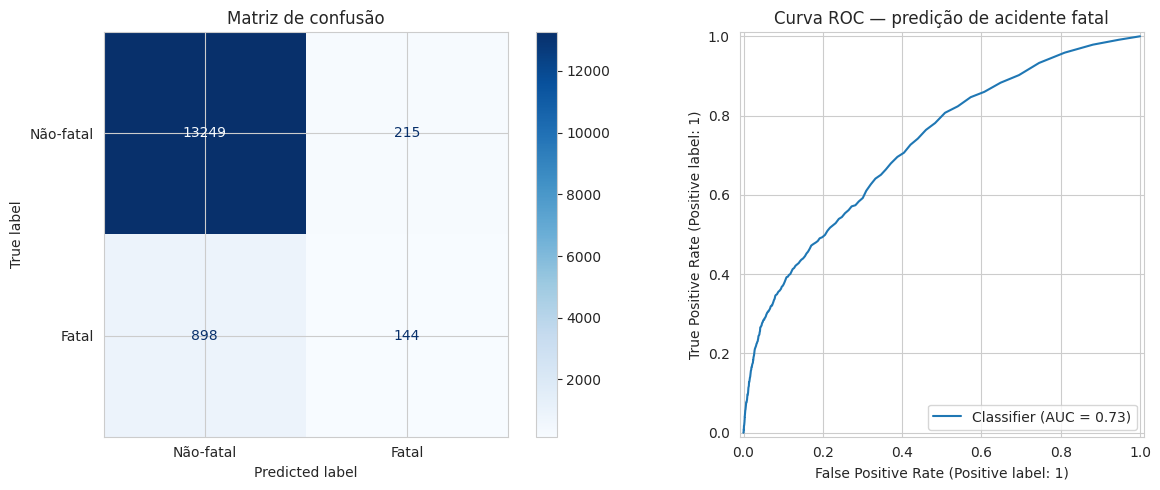

In [ ]:
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Não-fatal", "Fatal"]))
print(f"AUC-ROC: {roc_auc_score(y_test, y_prob):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Não-fatal", "Fatal"], cmap="Blues", ax=ax[0])
ax[0].set_title("Matriz de confusão")
RocCurveDisplay.from_predictions(y_test, y_prob, ax=ax[1])
ax[1].set_title("Curva ROC — predição de acidente fatal")
plt.tight_layout()
plt.show()

## 10. Ajuste de limiar (threshold)

O corte de decisão pode ser calibrado. Para uma ferramenta preventiva, aceitar
mais falsos alarmes em troca de detectar mais fatais costuma valer a pena.

In [ ]:
limiares = [0.5, 0.4, 0.3, 0.2, 0.15, 0.1]
linhas = []
for t in limiares:
    pred_t = (y_prob >= t).astype(int)
    tp = int(((pred_t == 1) & (y_test == 1)).sum())
    fp = int(((pred_t == 1) & (y_test == 0)).sum())
    fn = int(((pred_t == 0) & (y_test == 1)).sum())
    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0
    linhas.append({"limiar": t, "recall_fatal": round(recall, 3),
                   "precision_fatal": round(precision, 3),
                   "alertas_emitidos": tp + fp})

print(pd.DataFrame(linhas).to_string(index=False))

 limiar  recall_fatal  precision_fatal  alertas_emitidos
   0.50         0.139            0.399               363
   0.40         0.215            0.357               628
   0.30         0.289            0.295              1019
   0.20         0.380            0.221              1791
   0.15         0.445            0.182              2550
   0.10         0.539            0.148              3798


## 11. Importância dos atributos

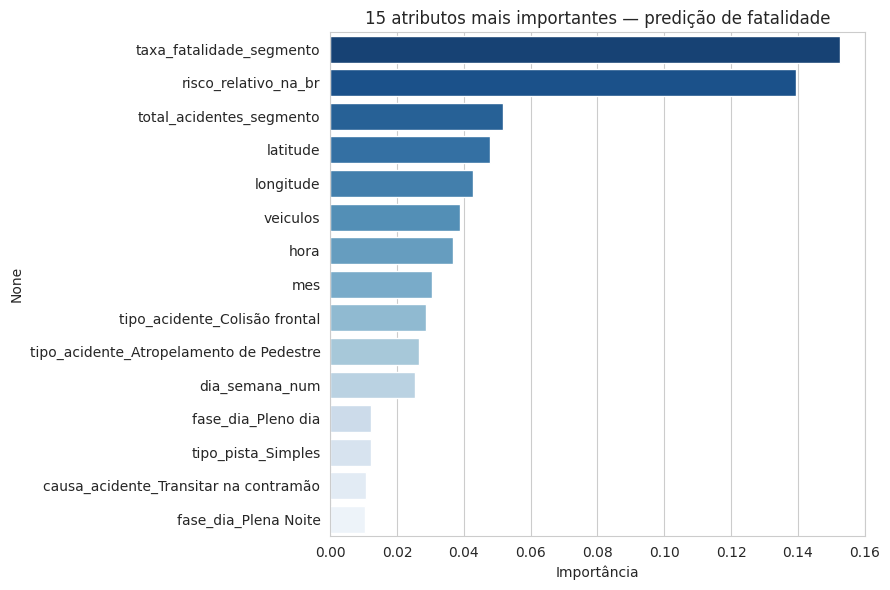

,importancia
taxa_fatalidade_segmento,0.152538
risco_relativo_na_br,0.139298
total_acidentes_segmento,0.051632
latitude,0.047730
longitude,0.042750
veiculos,0.038773
hora,0.036677
mes,0.030565
tipo_acidente_Colisão frontal,0.028680
tipo_acidente_Atropelamento de Pedestre,0.026670


In [ ]:
ohe = modelo.named_steps["preprocessador"].named_transformers_["cat"].named_steps["onehot"]
nomes = list(ohe.get_feature_names_out(features_categoricas)) + features_numericas
importancias = modelo.named_steps["classificador"].feature_importances_

imp = pd.Series(importancias, index=nomes).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette="Blues_r", legend=False)
plt.title("15 atributos mais importantes — predição de fatalidade")
plt.xlabel("Importância")
plt.tight_layout()
plt.show()
imp.to_frame("importancia")

## 12. Conclusões da análise exploratória

Cruzamentos que mostram padrões previsíveis de fatalidade — base conceitual do
SafeRoute.

In [ ]:
def taxa_fatalidade_por(coluna, min_registros=100):
    g = df.groupby(coluna).agg(
        total=("target_binario", "size"),
        fatais=("target_binario", "sum"),
    )
    g = g[g["total"] >= min_registros]
    g["taxa_fatalidade_%"] = (g["fatais"] / g["total"] * 100).round(2)
    return g.sort_values("taxa_fatalidade_%", ascending=False)

for coluna in ["fase_dia", "tipo_pista", "condicao_meteorologica", "tracado_via"]:
    if coluna in df.columns:
        print("=" * 60)
        print(f"Taxa de fatalidade por: {coluna}")
        print("=" * 60)
        print(taxa_fatalidade_por(coluna).to_string())
        print()

Taxa de fatalidade por: fase_dia
             total  fatais  taxa_fatalidade_%
fase_dia                                     
Amanhecer     3447     386              11.20
Plena Noite  24781    2522              10.18
Anoitecer     3926     253               6.44
Pleno dia    40375    2048               5.07

Taxa de fatalidade por: tipo_pista
            total  fatais  taxa_fatalidade_%
tipo_pista                                  
Simples     34733    3423               9.86
Dupla       30782    1501               4.88
Múltipla     7014     285               4.06

Taxa de fatalidade por: condicao_meteorologica
                        total  fatais  taxa_fatalidade_%
condicao_meteorologica                                  
Nevoeiro/Neblina          553      60              10.85
Ignorado                 1000      99               9.90
Vento                     104       9               8.65
Céu Claro               46375    3418               7.37
Nublado                 11435     830   

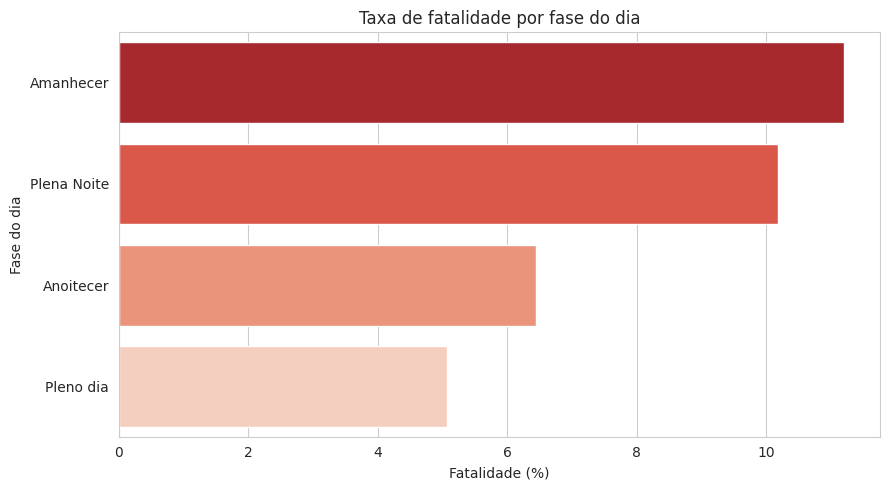

In [ ]:
if "fase_dia" in df.columns:
    t = taxa_fatalidade_por("fase_dia").reset_index()
    plt.figure(figsize=(9, 5))
    sns.barplot(data=t, x="taxa_fatalidade_%", y="fase_dia",
                hue="fase_dia", palette="Reds_r", legend=False)
    plt.title("Taxa de fatalidade por fase do dia")
    plt.xlabel("Fatalidade (%)"); plt.ylabel("Fase do dia")
    plt.tight_layout()
    plt.show()

---
### Próximos passos (Sprint 3)

Evoluir da classificação por acidente individual para o **modelo agregado de
risco por segmento**, usando `risco_relativo_na_br` como base do índice de risco
exibido no mapa interativo do SafeRoute.